Install libraries

In [1]:
!pip install -q wfdb snntorch seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.6/133.6 kB 10.8 MB/s eta 0:00:00


Import libraries

In [2]:
import os
import zipfile
import glob
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import wfdb

from scipy.signal import butter, filtfilt, resample

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import snntorch as snn
from snntorch import surrogate

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Libraries imported successfully.
PyTorch version: 2.11.0+cu128
CUDA available: True


Set random seed and device

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", DEVICE)

Using device: cuda


Upload the PhysioNet ZIP

In [4]:
from google.colab import files

uploaded = files.upload()

zip_name = list(uploaded.keys())[0]

print("Uploaded file:", zip_name)
print("File size: %.2f MB" % (os.path.getsize(zip_name) / (1024 * 1024)))

Saving mit-bih-arrhythmia-database-1.0.0.zip to mit-bih-arrhythmia-database-1.0.0.zip
Uploaded file: mit-bih-arrhythmia-database-1.0.0.zip
File size: 73.46 MB


Extract the ZIP

In [5]:
EXTRACT_DIR = "/content/mitdb"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Extraction completed.")

Extraction completed.


Find the actual MIT-BIH directory

In [6]:
print("Searching for MIT-BIH files...\n")

hea_files = glob.glob(
    os.path.join(EXTRACT_DIR, "**", "*.hea"),
    recursive=True
)

atr_files = glob.glob(
    os.path.join(EXTRACT_DIR, "**", "*.atr"),
    recursive=True
)

print("Header files found:", len(hea_files))
print("Annotation files found:", len(atr_files))

print("\nExample files:")

for f in hea_files[:5]:
    print(f)

Searching for MIT-BIH files...

Header files found: 71
Annotation files found: 72

Example files:
/content/mitdb/mit-bih-arrhythmia-database-1.0.0/208.hea
/content/mitdb/mit-bih-arrhythmia-database-1.0.0/233.hea
/content/mitdb/mit-bih-arrhythmia-database-1.0.0/115.hea
/content/mitdb/mit-bih-arrhythmia-database-1.0.0/106.hea
/content/mitdb/mit-bih-arrhythmia-database-1.0.0/207.hea


Automatically find the directory containing record 100

In [7]:
record_100 = None

for root, dirs, files_list in os.walk(EXTRACT_DIR):
    if "100.hea" in files_list and "100.dat" in files_list:
        record_100 = root
        break

if record_100 is None:
    raise FileNotFoundError("Could not find MIT-BIH record 100.")

print("MIT-BIH directory:")
print(record_100)

MIT-BIH directory:
/content/mitdb/mit-bih-arrhythmia-database-1.0.0


Test WFDB loading

In [8]:
record_path = os.path.join(record_100, "100")

record = wfdb.rdrecord(record_path)
annotation = wfdb.rdann(record_path, "atr")

print("Sampling frequency:", record.fs)
print("Number of samples:", record.sig_len)
print("Number of channels:", record.n_sig)
print("Channel names:", record.sig_name)
print("Number of annotations:", len(annotation.sample))

Sampling frequency: 360
Number of samples: 650000
Number of channels: 2
Channel names: ['MLII', 'V5']
Number of annotations: 2274


Inspect ECG signal

In [9]:
signal = record.p_signal[:, 0]

print("Signal shape:", signal.shape)
print("First 10 ECG values:")
print(signal[:10])

Signal shape: (650000,)
First 10 ECG values:
[-0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.12  -0.135]


Plot raw ECG

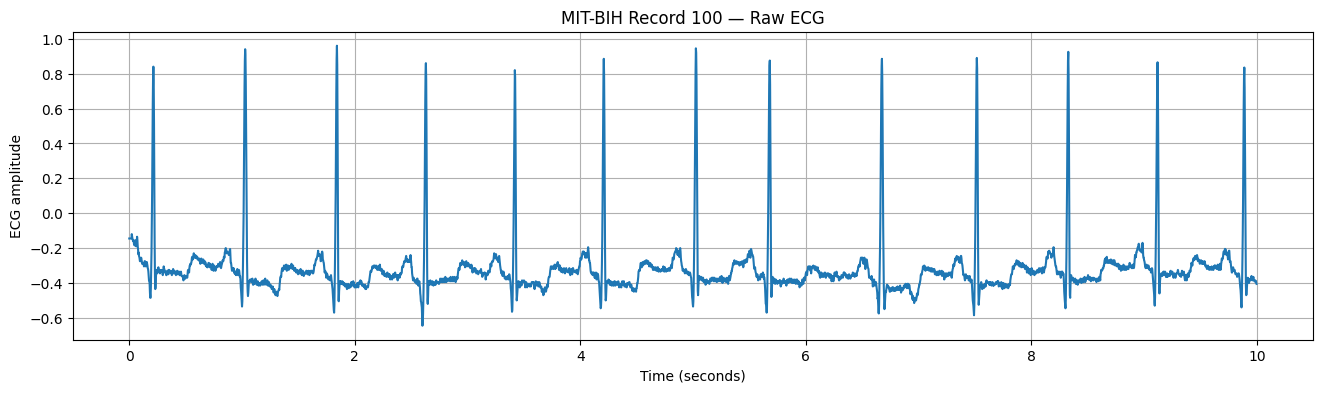

In [10]:
FS = int(record.fs)

duration = 10  # seconds
samples = duration * FS

plt.figure(figsize=(16, 4))

plt.plot(
    np.arange(samples) / FS,
    signal[:samples]
)

plt.xlabel("Time (seconds)")
plt.ylabel("ECG amplitude")
plt.title("MIT-BIH Record 100 — Raw ECG")
plt.grid(True)

plt.show()

Plot ECG with annotations

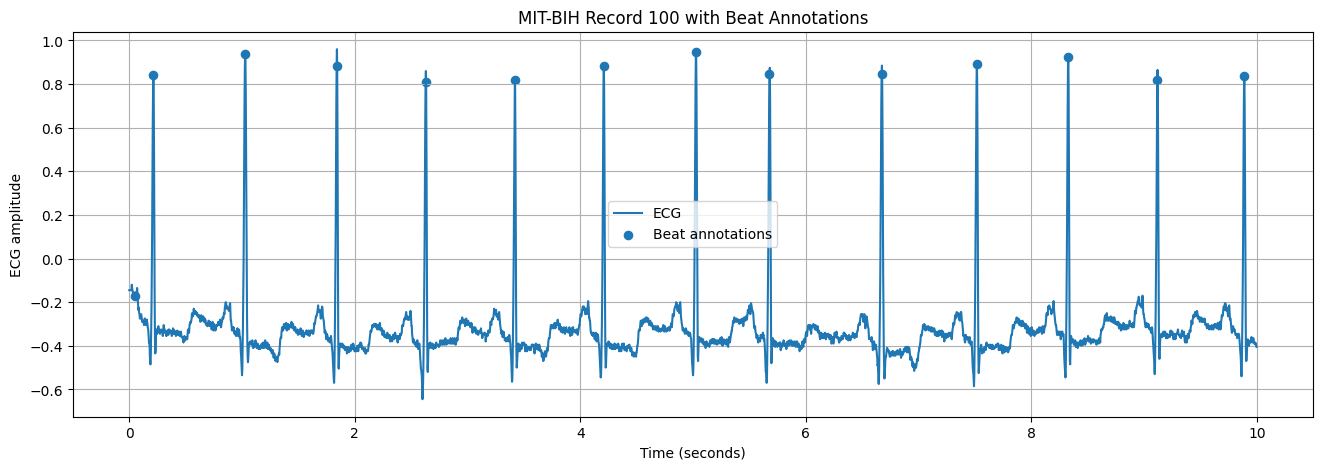

In [11]:
samples = 10 * FS

ann_samples = annotation.sample
ann_symbols = annotation.symbol

mask = ann_samples < samples

plt.figure(figsize=(16, 5))

plt.plot(
    np.arange(samples) / FS,
    signal[:samples],
    label="ECG"
)

plt.scatter(
    ann_samples[mask] / FS,
    signal[ann_samples[mask]],
    s=35,
    marker="o",
    label="Beat annotations"
)

plt.xlabel("Time (seconds)")
plt.ylabel("ECG amplitude")
plt.title("MIT-BIH Record 100 with Beat Annotations")
plt.legend()
plt.grid(True)

plt.show()

Define all MIT-BIH records

In [12]:
MITBIH_RECORDS = [
    100, 101, 102, 103, 104, 105, 106, 107,
    108, 109, 111, 112, 113, 114, 115, 116,
    117, 118, 119, 121, 122, 123, 124,
    200, 201, 202, 203, 205, 207, 208, 209,
    210, 212, 213, 214, 215, 217, 219, 220,
    221, 222, 223, 228, 230, 231, 232, 233,
    234
]

MITBIH_RECORDS = [str(x) for x in MITBIH_RECORDS]

print("Number of records:", len(MITBIH_RECORDS))

Number of records: 48


Project configuration

In [13]:
FS = 360

# Beat window
PRE_SEC = 0.20
POST_SEC = 0.40

PRE_SAMPLES = int(PRE_SEC * FS)
POST_SAMPLES = int(POST_SEC * FS)

# Final fixed-size beat
N_SAMPLES = 128

# Level-crossing threshold
LC_THRESHOLD = 0.25

BATCH_SIZE = 128

print("Sampling frequency:", FS)
print("Beat window:", PRE_SAMPLES, "+", POST_SAMPLES, "samples")
print("Final beat length:", N_SAMPLES)
print("LC threshold:", LC_THRESHOLD)

Sampling frequency: 360
Beat window: 72 + 144 samples
Final beat length: 128
LC threshold: 0.25


Find record path automatically

In [14]:
def find_record_path(record_id):
    record_id = str(record_id)

    matches = glob.glob(
        os.path.join(
            EXTRACT_DIR,
            "**",
            record_id + ".hea"
        ),
        recursive=True
    )

    if len(matches) == 0:
        raise FileNotFoundError(
            f"Record {record_id} not found."
        )

    hea_path = matches[0]

    return os.path.splitext(hea_path)[0]


print(find_record_path("100"))

/content/mitdb/mit-bih-arrhythmia-database-1.0.0/100


ECG preprocessing

In [15]:
def bandpass_filter(signal, fs, lowcut=0.5, highcut=40.0, order=4):

    nyquist = 0.5 * fs

    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(
        order,
        [low, high],
        btype="band"
    )

    filtered = filtfilt(b, a, signal)

    return filtered

Normalize ECG beat

In [16]:
def normalize_beat(beat):

    beat = np.asarray(beat, dtype=np.float32)

    median = np.median(beat)
    std = np.std(beat)

    if std < 1e-8:
        return beat - median

    beat = (beat - median) / std

    return beat

Extract one beat

In [17]:
def extract_beat(signal, sample_index):

    start = sample_index - PRE_SAMPLES
    end = sample_index + POST_SAMPLES

    if start < 0 or end > len(signal):
        return None

    beat = signal[start:end]

    beat = resample(
        beat,
        N_SAMPLES
    )

    beat = normalize_beat(beat)

    return beat.astype(np.float32)

Define normal/abnormal classes

In [18]:
NORMAL_SYMBOLS = {
    "N",   # Normal beat
    "L",   # Left bundle branch block beat
    "R",   # Right bundle branch block beat
    "e",   # Atrial escape beat
    "j"    # Nodal (junctional) escape beat
}

BEAT_SYMBOLS = {
    "N", "L", "R", "e", "j",
    "A", "a", "J", "S",
    "V", "E",
    "F", "f",
    "Q", "?",
    "/", "U"
}

print("Normal symbols:", NORMAL_SYMBOLS)
print("Total selected beat symbols:", len(BEAT_SYMBOLS))

Normal symbols: {'R', 'L', 'j', 'e', 'N'}
Total selected beat symbols: 17


Load one record

In [19]:
def load_record(record_id):

    record_path = find_record_path(record_id)

    record = wfdb.rdrecord(record_path)

    annotation = wfdb.rdann(
        record_path,
        "atr"
    )

    signal = record.p_signal[:, 0]

    fs = record.fs

    return signal, annotation, fs

Build dataset from all records

In [20]:
def process_record(record_id):

    signal, annotation, fs = load_record(record_id)

    # Bandpass filter the entire ECG
    filtered_signal = bandpass_filter(
        signal,
        fs
    )

    X = []
    y = []

    for sample, symbol in zip(
        annotation.sample,
        annotation.symbol
    ):

        if symbol not in BEAT_SYMBOLS:
            continue

        beat = extract_beat(
            filtered_signal,
            sample
        )

        if beat is None:
            continue

        label = 0 if symbol in NORMAL_SYMBOLS else 1

        X.append(beat)
        y.append(label)

    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)

Test with one record

In [21]:
X100, y100 = process_record("100")

print("Record 100:")
print("X shape:", X100.shape)
print("y shape:", y100.shape)

print("\nClass distribution:")
print(pd.Series(y100).value_counts())

Record 100:
X shape: (2272, 128)
y shape: (2272,)

Class distribution:
0    2238
1      34
Name: count, dtype: int64


Process all 48 records

In [22]:
all_X = []
all_y = []
all_record_ids = []

start_time = time.time()

for i, record_id in enumerate(MITBIH_RECORDS):

    try:

        X_record, y_record = process_record(
            record_id
        )

        all_X.append(X_record)
        all_y.append(y_record)

        all_record_ids.extend(
            [record_id] * len(y_record)
        )

        print(
            f"[{i+1:02d}/{len(MITBIH_RECORDS)}] "
            f"Record {record_id}: "
            f"{len(y_record)} beats"
        )

    except Exception as e:

        print(
            f"ERROR in record {record_id}: {e}"
        )

X = np.concatenate(all_X)
y = np.concatenate(all_y)

record_ids = np.array(all_record_ids)

print("\nDataset created.")
print("X shape:", X.shape)
print("y shape:", y.shape)

print(
    "Processing time: %.2f minutes"
    % ((time.time() - start_time) / 60)
)

[01/48] Record 100: 2272 beats
[02/48] Record 101: 1865 beats
[03/48] Record 102: 2187 beats
[04/48] Record 103: 2083 beats
[05/48] Record 104: 2228 beats
[06/48] Record 105: 2572 beats
[07/48] Record 106: 2027 beats
[08/48] Record 107: 2137 beats
[09/48] Record 108: 1763 beats
[10/48] Record 109: 2531 beats
[11/48] Record 111: 2124 beats
[12/48] Record 112: 2538 beats
[13/48] Record 113: 1794 beats
[14/48] Record 114: 1879 beats
[15/48] Record 115: 1952 beats
[16/48] Record 116: 2411 beats
[17/48] Record 117: 1534 beats
[18/48] Record 118: 2277 beats
[19/48] Record 119: 1987 beats
[20/48] Record 121: 1862 beats
[21/48] Record 122: 2475 beats
[22/48] Record 123: 1517 beats
[23/48] Record 124: 1618 beats
[24/48] Record 200: 2600 beats
[25/48] Record 201: 1963 beats
[26/48] Record 202: 2135 beats
[27/48] Record 203: 2980 beats
[28/48] Record 205: 2655 beats
[29/48] Record 207: 1859 beats
[30/48] Record 208: 2953 beats
[31/48] Record 209: 3004 beats
[32/48] Record 210: 2648 beats
[33/48] 

Check class distribution

Normal beats: 90600
Abnormal beats: 18860


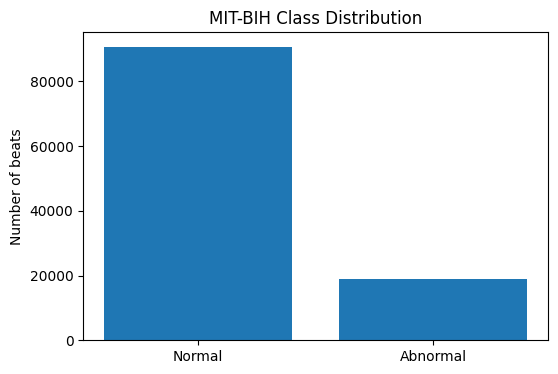

In [23]:
class_counts = pd.Series(y).value_counts().sort_index()

print("Normal beats:", class_counts.get(0, 0))
print("Abnormal beats:", class_counts.get(1, 0))

plt.figure(figsize=(6, 4))

plt.bar(
    ["Normal", "Abnormal"],
    [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ]
)

plt.ylabel("Number of beats")
plt.title("MIT-BIH Class Distribution")

plt.show()

Plot sample beats

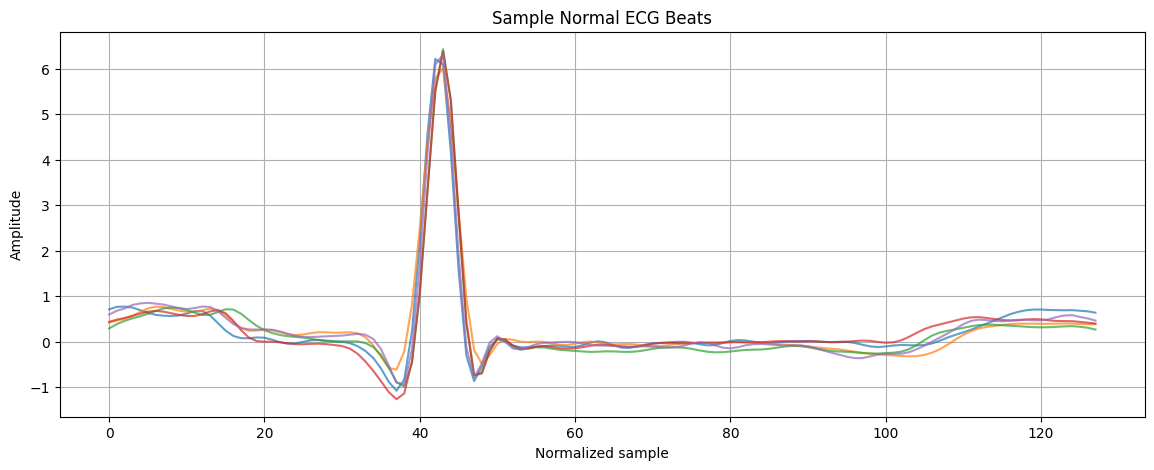

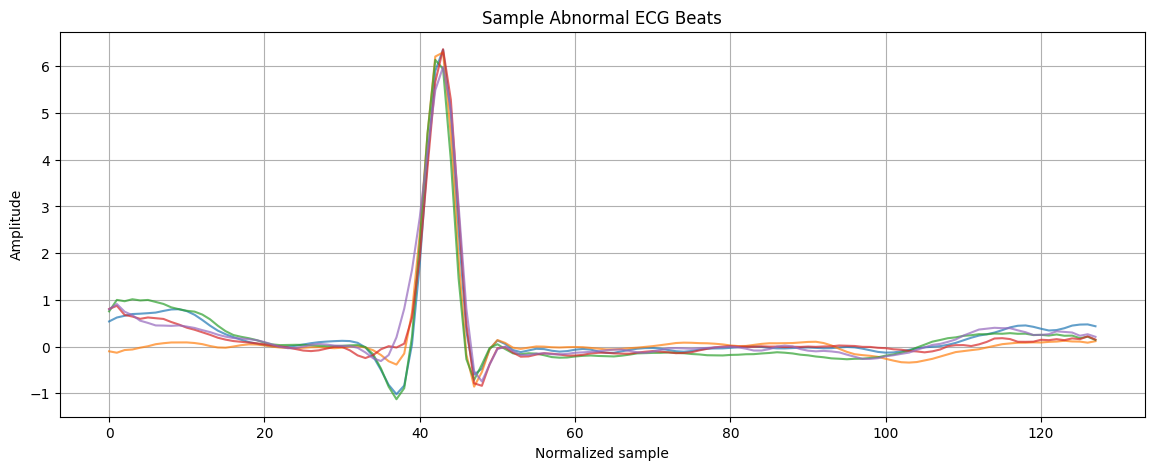

In [24]:
normal_idx = np.where(y == 0)[0]
abnormal_idx = np.where(y == 1)[0]

plt.figure(figsize=(14, 5))

for idx in normal_idx[:5]:
    plt.plot(
        X[idx],
        alpha=0.7
    )

plt.title("Sample Normal ECG Beats")
plt.xlabel("Normalized sample")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()


plt.figure(figsize=(14, 5))

for idx in abnormal_idx[:5]:
    plt.plot(
        X[idx],
        alpha=0.7
    )

plt.title("Sample Abnormal ECG Beats")
plt.xlabel("Normalized sample")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()

Record-level train/validation/test split

In [25]:
from sklearn.model_selection import train_test_split

unique_records = np.unique(record_ids)

train_records, temp_records = train_test_split(
    unique_records,
    test_size=0.30,
    random_state=SEED
)

val_records, test_records = train_test_split(
    temp_records,
    test_size=0.50,
    random_state=SEED
)

train_mask = np.isin(record_ids, train_records)
val_mask = np.isin(record_ids, val_records)
test_mask = np.isin(record_ids, test_records)

X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("Train records:", train_records)
print("Validation records:", val_records)
print("Test records:", test_records)

print("\nTrain:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train records: ['114' '118' '232' '116' '109' '117' '208' '212' '233' '100' '210' '209'
 '105' '112' '214' '101' '231' '123' '102' '217' '215' '200' '223' '111'
 '124' '119' '234' '122' '107' '228' '115' '207' '220']
Validation records: ['213' '201' '121' '108' '106' '230' '113']
Test records: ['202' '103' '205' '221' '219' '104' '203' '222']

Train: (75401, 128)
Validation: (14915, 128)
Test: (19144, 128)


Check split class distributions

In [26]:
print("TRAIN")
print(pd.Series(y_train).value_counts())

print("\nVALIDATION")
print(pd.Series(y_val).value_counts())

print("\nTEST")
print(pd.Series(y_test).value_counts())

TRAIN
0    61386
1    14015
Name: count, dtype: int64

VALIDATION
0    13425
1     1490
Name: count, dtype: int64

TEST
0    15789
1     3355
Name: count, dtype: int64


## MODEL 1 — RANDOM FOREST

Extract morphology-proxy features

In [27]:
def extract_features(beat):

    r_idx = np.argmax(beat)

    features = [

        # P-wave proxy
        np.max(beat[:int(0.30 * len(beat))]),

        # Q/S amplitude proxy
        np.min(beat),

        # R amplitude
        np.max(beat),

        # T-wave proxy
        np.max(
            beat[int(0.65 * len(beat)):]
        ),

        # Pre-R mean
        np.mean(
            beat[:r_idx]
        ) if r_idx > 0 else 0,

        # Post-R mean
        np.mean(
            beat[r_idx:]
        ) if r_idx < len(beat) else 0,

        # Energy
        np.sum(beat ** 2),

        # Maximum slope
        np.max(
            np.abs(np.diff(beat))
        )
    ]

    return features

Create RF features

In [28]:
X_train_rf = np.array([
    extract_features(beat)
    for beat in X_train
])

X_val_rf = np.array([
    extract_features(beat)
    for beat in X_val
])

X_test_rf = np.array([
    extract_features(beat)
    for beat in X_test
])

print("RF training shape:", X_train_rf.shape)
print("RF validation shape:", X_val_rf.shape)
print("RF test shape:", X_test_rf.shape)

RF training shape: (75401, 8)
RF validation shape: (14915, 8)
RF test shape: (19144, 8)


Train Random Forest

In [29]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

rf_start = time.time()

rf_model.fit(
    X_train_rf,
    y_train
)

rf_train_time = time.time() - rf_start

print(
    "Random Forest training time: %.2f seconds"
    % rf_train_time
)

Random Forest training time: 56.50 seconds


RF prediction

In [30]:
rf_pred = rf_model.predict(
    X_test_rf
)

rf_prob = rf_model.predict_proba(
    X_test_rf
)[:, 1]

RF evaluation

In [31]:
def calculate_metrics(y_true, y_pred, y_prob):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1": f1,
        "ROC-AUC": auc
    }


rf_metrics = calculate_metrics(
    y_test,
    rf_pred,
    rf_prob
)

rf_metrics

{'Accuracy': 0.8918721270371918,
 'Precision': 0.6722982032716546,
 'Sensitivity': 0.7472429210134128,
 'Specificity': np.float64(0.9226043447970106),
 'F1': 0.7077922077922078,
 'ROC-AUC': np.float64(0.888076467430635)}

RF confusion matrix

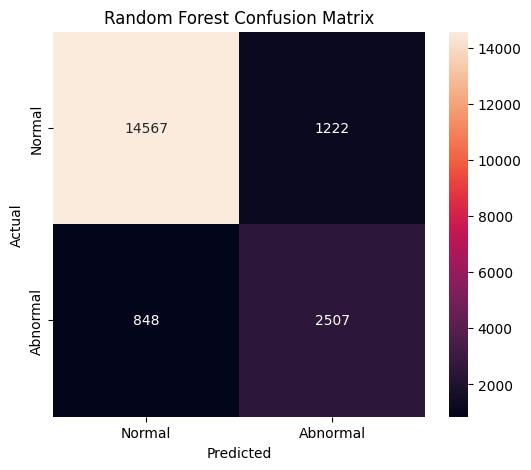

In [32]:
cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Normal", "Abnormal"],
    yticklabels=["Normal", "Abnormal"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

## MODEL 2 — 1D CNN

Convert ECG data to PyTorch tensors

In [33]:
X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
).unsqueeze(1)

X_val_tensor = torch.tensor(
    X_val,
    dtype=torch.float32
).unsqueeze(1)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
).unsqueeze(1)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

print(X_train_tensor.shape)

torch.Size([75401, 1, 128])


Create DataLoaders

In [34]:
train_dataset = torch.utils.data.TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = torch.utils.data.TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = torch.utils.data.TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Define 1D CNN

In [35]:
class ECG_CNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv1d(
                1, 16,
                kernel_size=7,
                padding=3
            ),

            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(
                16, 32,
                kernel_size=5,
                padding=2
            ),

            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(
                32, 64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Linear(
            64,
            2
        )

    def forward(self, x):

        x = self.features(x)

        x = x.squeeze(-1)

        x = self.classifier(x)

        return x


cnn_model = ECG_CNN().to(DEVICE)

print(cnn_model)

ECG_CNN(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Linear(in_features=64, out_features=2, bias=True)
)


CNN class weights

In [36]:
class_counts = np.bincount(y_train)

class_weights = (
    len(y_train) /
    (2 * class_counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(DEVICE)

print("Class weights:", class_weights)

Class weights: tensor([0.6142, 2.6900], device='cuda:0')


CNN training setup

In [37]:
cnn_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

cnn_optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

CNN training

In [38]:
NUM_EPOCHS_CNN = 10

cnn_train_losses = []
cnn_val_losses = []

cnn_train_acc = []
cnn_val_acc = []

cnn_start = time.time()

for epoch in range(NUM_EPOCHS_CNN):

    # -----------------
    # Training
    # -----------------

    cnn_model.train()

    running_loss = 0
    correct = 0
    total = 0

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(DEVICE)
        batch_y = batch_y.to(DEVICE)

        cnn_optimizer.zero_grad()

        outputs = cnn_model(batch_x)

        loss = cnn_criterion(
            outputs,
            batch_y
        )

        loss.backward()

        cnn_optimizer.step()

        running_loss += (
            loss.item() *
            batch_x.size(0)
        )

        predictions = outputs.argmax(1)

        correct += (
            predictions == batch_y
        ).sum().item()

        total += batch_y.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # -----------------
    # Validation
    # -----------------

    cnn_model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            batch_x = batch_x.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            outputs = cnn_model(batch_x)

            loss = cnn_criterion(
                outputs,
                batch_y
            )

            val_loss += (
                loss.item() *
                batch_x.size(0)
            )

            predictions = outputs.argmax(1)

            val_correct += (
                predictions == batch_y
            ).sum().item()

            val_total += batch_y.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    cnn_train_losses.append(train_loss)
    cnn_val_losses.append(val_loss)

    cnn_train_acc.append(train_accuracy)
    cnn_val_acc.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS_CNN}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

cnn_train_time = time.time() - cnn_start

print(
    "\nCNN training time: %.2f minutes"
    % (cnn_train_time / 60)
)

Epoch [1/10] Train Loss: 0.2385 Val Loss: 0.8971 Train Acc: 0.9216 Val Acc: 0.5738
Epoch [2/10] Train Loss: 0.1442 Val Loss: 0.5055 Train Acc: 0.9645 Val Acc: 0.8391
Epoch [3/10] Train Loss: 0.1221 Val Loss: 2.1312 Train Acc: 0.9695 Val Acc: 0.2542
Epoch [4/10] Train Loss: 0.1139 Val Loss: 2.5059 Train Acc: 0.9726 Val Acc: 0.2080
Epoch [5/10] Train Loss: 0.1063 Val Loss: 0.7125 Train Acc: 0.9739 Val Acc: 0.7165
Epoch [6/10] Train Loss: 0.1036 Val Loss: 1.2105 Train Acc: 0.9746 Val Acc: 0.4859
Epoch [7/10] Train Loss: 0.0973 Val Loss: 0.4450 Train Acc: 0.9762 Val Acc: 0.8366
Epoch [8/10] Train Loss: 0.0931 Val Loss: 0.4383 Train Acc: 0.9775 Val Acc: 0.9007
Epoch [9/10] Train Loss: 0.0890 Val Loss: 0.6535 Train Acc: 0.9787 Val Acc: 0.6937
Epoch [10/10] Train Loss: 0.0861 Val Loss: 0.3661 Train Acc: 0.9790 Val Acc: 0.9393

CNN training time: 1.96 minutes



CNN learning curves

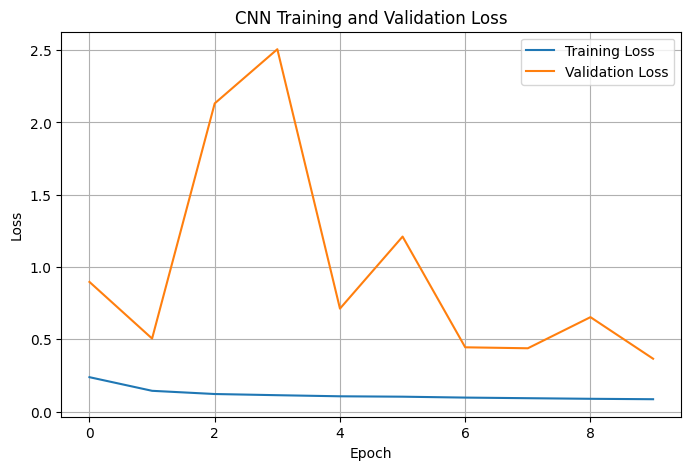

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(
    cnn_train_losses,
    label="Training Loss"
)

plt.plot(
    cnn_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

CNN predictions

In [40]:
cnn_model.eval()

cnn_predictions = []
cnn_probabilities = []

cnn_inference_start = time.time()

with torch.no_grad():

    for batch_x, batch_y in test_loader:

        batch_x = batch_x.to(DEVICE)

        outputs = cnn_model(batch_x)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = outputs.argmax(1)

        cnn_predictions.extend(
            predictions.cpu().numpy()
        )

        cnn_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )

cnn_inference_time = time.time() - cnn_inference_start

cnn_predictions = np.array(
    cnn_predictions
)

cnn_probabilities = np.array(
    cnn_probabilities
)

print(
    "CNN inference time: %.2f seconds"
    % cnn_inference_time
)

CNN inference time: 2.54 seconds


CNN metrics

In [41]:
cnn_metrics = calculate_metrics(
    y_test,
    cnn_predictions,
    cnn_probabilities
)

cnn_metrics

{'Accuracy': 0.861105307145842,
 'Precision': 0.5804810360777058,
 'Sensitivity': 0.7481371087928465,
 'Specificity': np.float64(0.8851098866299323),
 'F1': 0.6537309545513739,
 'ROC-AUC': np.float64(0.9029211984158829)}

CNN confusion matrix

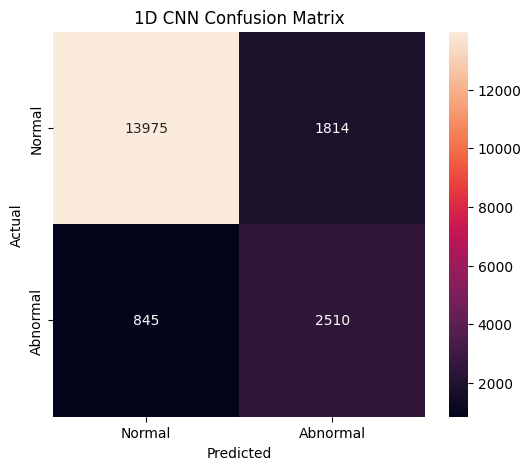

In [42]:
cm = confusion_matrix(
    y_test,
    cnn_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Normal", "Abnormal"],
    yticklabels=["Normal", "Abnormal"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("1D CNN Confusion Matrix")

plt.show()

MODEL 3 — LEVEL CROSSING ENCODER

In [43]:
def level_crossing_encode(
    beat,
    threshold=0.25
):

    spikes = np.zeros(
        len(beat),
        dtype=np.float32
    )

    reference = beat[0]

    for t in range(1, len(beat)):

        difference = (
            beat[t] - reference
        )

        if difference >= threshold:

            spikes[t] = 1

            reference += threshold

        elif difference <= -threshold:

            spikes[t] = -1

            reference -= threshold

    return spikes

Test LC encoding

In [44]:
example_beat = X_test[0]

example_spikes = level_crossing_encode(
    example_beat,
    LC_THRESHOLD
)

print("Number of events:", np.count_nonzero(example_spikes))
print("Total samples:", len(example_spikes))

print(
    "Event rate:",
    np.count_nonzero(example_spikes) / len(example_spikes)
)

Number of events: 26
Total samples: 128
Event rate: 0.203125


Visualize Raw ECG → LC spikes

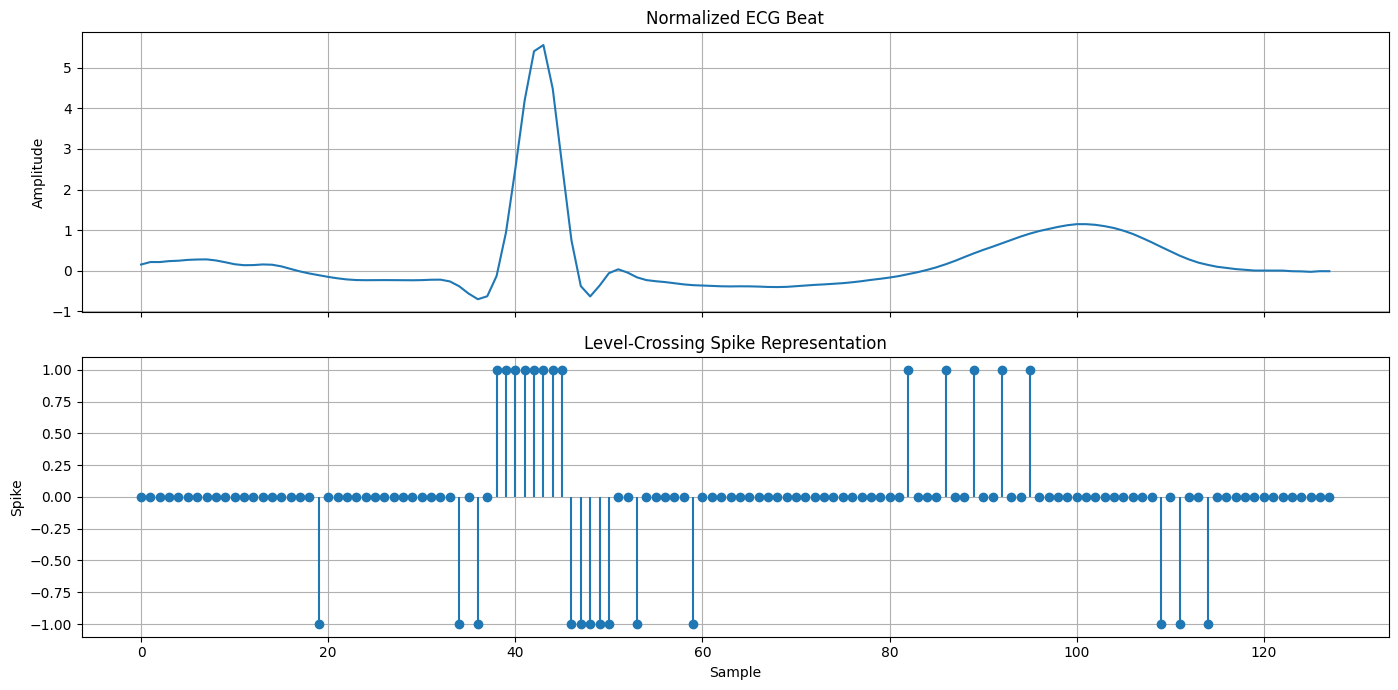

In [45]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 7),
    sharex=True
)

axes[0].plot(
    example_beat
)

axes[0].set_title(
    "Normalized ECG Beat"
)

axes[0].set_ylabel(
    "Amplitude"
)

axes[0].grid(True)


axes[1].stem(
    example_spikes,
    basefmt=" "
)

axes[1].set_title(
    "Level-Crossing Spike Representation"
)

axes[1].set_xlabel(
    "Sample"
)

axes[1].set_ylabel(
    "Spike"
)

axes[1].grid(True)

plt.tight_layout()

plt.show()

Convert entire dataset to LC spikes

In [46]:
X_train_spikes = np.array([
    level_crossing_encode(
        beat,
        LC_THRESHOLD
    )
    for beat in X_train
])

X_val_spikes = np.array([
    level_crossing_encode(
        beat,
        LC_THRESHOLD
    )
    for beat in X_val
])

X_test_spikes = np.array([
    level_crossing_encode(
        beat,
        LC_THRESHOLD
    )
    for beat in X_test
])

print(
    "Train spikes:",
    X_train_spikes.shape
)

print(
    "Test spikes:",
    X_test_spikes.shape
)

Train spikes: (75401, 128)
Test spikes: (19144, 128)


Calculate event sparsity

In [47]:
train_event_rate = np.mean(
    np.abs(X_train_spikes) > 0
)

test_event_rate = np.mean(
    np.abs(X_test_spikes) > 0
)

print(
    "Training event rate:",
    train_event_rate
)

print(
    "Test event rate:",
    test_event_rate
)

print(
    "Test sparsity:",
    1 - test_event_rate
)

Training event rate: 0.24329180398801076
Test event rate: 0.23552989840158797
Test sparsity: 0.764470101598412


Create SNN tensors

In [48]:
X_train_snn = torch.tensor(
    X_train_spikes,
    dtype=torch.float32
)

X_val_snn = torch.tensor(
    X_val_spikes,
    dtype=torch.float32
)

X_test_snn = torch.tensor(
    X_test_spikes,
    dtype=torch.float32
)

y_train_snn = torch.tensor(
    y_train,
    dtype=torch.long
)

y_val_snn = torch.tensor(
    y_val,
    dtype=torch.long
)

y_test_snn = torch.tensor(
    y_test,
    dtype=torch.long
)

print(
    X_train_snn.shape
)

torch.Size([75401, 128])


SNN DataLoaders

In [49]:
snn_train_dataset = torch.utils.data.TensorDataset(
    X_train_snn,
    y_train_snn
)

snn_val_dataset = torch.utils.data.TensorDataset(
    X_val_snn,
    y_val_snn
)

snn_test_dataset = torch.utils.data.TensorDataset(
    X_test_snn,
    y_test_snn
)

snn_train_loader = DataLoader(
    snn_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

snn_val_loader = DataLoader(
    snn_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

snn_test_loader = DataLoader(
    snn_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Define SNN

In [50]:
class ECG_SNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.fc1 = nn.Linear(
            1,
            32
        )

        self.lif1 = snn.Leaky(
            beta=0.90,
            spike_grad=surrogate.fast_sigmoid(
                slope=25
            )
        )

        self.fc2 = nn.Linear(
            32,
            32
        )

        self.lif2 = snn.Leaky(
            beta=0.90,
            spike_grad=surrogate.fast_sigmoid(
                slope=25
            )
        )

        self.fc3 = nn.Linear(
            32,
            2
        )

    def forward(self, x):

        batch_size = x.size(0)

        mem1 = self.lif1.init_leaky()

        mem2 = self.lif2.init_leaky()

        outputs = []

        for t in range(x.size(1)):

            current = x[:, t].unsqueeze(1)

            cur1 = self.fc1(current)

            spk1, mem1 = self.lif1(
                cur1,
                mem1
            )

            cur2 = self.fc2(spk1)

            spk2, mem2 = self.lif2(
                cur2,
                mem2
            )

            out = self.fc3(spk2)

            outputs.append(out)

        outputs = torch.stack(
            outputs,
            dim=0
        )

        return outputs


snn_model = ECG_SNN().to(DEVICE)

print(snn_model)

ECG_SNN(
  (fc1): Linear(in_features=1, out_features=32, bias=True)
  (lif1): Leaky()
  (fc2): Linear(in_features=32, out_features=32, bias=True)
  (lif2): Leaky()
  (fc3): Linear(in_features=32, out_features=2, bias=True)
)


SNN class weights and optimizer

In [51]:
snn_class_weights = (
    len(y_train) /
    (2 * np.bincount(y_train))
)

snn_class_weights = torch.tensor(
    snn_class_weights,
    dtype=torch.float32
).to(DEVICE)

snn_criterion = nn.CrossEntropyLoss(
    weight=snn_class_weights
)

snn_optimizer = torch.optim.Adam(
    snn_model.parameters(),
    lr=0.001
)

print(
    "SNN class weights:",
    snn_class_weights
)

SNN class weights: tensor([0.6142, 2.6900], device='cuda:0')


Train SNN

In [52]:
NUM_EPOCHS_SNN = 10

snn_train_losses = []
snn_val_losses = []

snn_train_acc = []
snn_val_acc = []

snn_start = time.time()

for epoch in range(NUM_EPOCHS_SNN):

    # -----------------
    # Training
    # -----------------

    snn_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for batch_x, batch_y in snn_train_loader:

        batch_x = batch_x.to(DEVICE)
        batch_y = batch_y.to(DEVICE)

        snn_optimizer.zero_grad()

        outputs = snn_model(
            batch_x
        )

        # Sum output over time
        logits = outputs.sum(
            dim=0
        )

        loss = snn_criterion(
            logits,
            batch_y
        )

        loss.backward()

        snn_optimizer.step()

        total_loss += (
            loss.item() *
            batch_x.size(0)
        )

        predictions = logits.argmax(
            dim=1
        )

        correct += (
            predictions == batch_y
        ).sum().item()

        total += batch_y.size(0)

    train_loss = total_loss / total
    train_accuracy = correct / total

    # -----------------
    # Validation
    # -----------------

    snn_model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for batch_x, batch_y in snn_val_loader:

            batch_x = batch_x.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            outputs = snn_model(
                batch_x
            )

            logits = outputs.sum(
                dim=0
            )

            loss = snn_criterion(
                logits,
                batch_y
            )

            val_loss += (
                loss.item() *
                batch_x.size(0)
            )

            predictions = logits.argmax(
                dim=1
            )

            val_correct += (
                predictions == batch_y
            ).sum().item()

            val_total += batch_y.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    snn_train_losses.append(
        train_loss
    )

    snn_val_losses.append(
        val_loss
    )

    snn_train_acc.append(
        train_accuracy
    )

    snn_val_acc.append(
        val_accuracy
    )

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS_SNN}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

snn_train_time = time.time() - snn_start

print(
    "\nSNN training time: %.2f minutes"
    % (snn_train_time / 60)
)

Epoch [1/10] Train Loss: 0.5759 Val Loss: 0.4371 Train Acc: 0.7489 Val Acc: 0.8716
Epoch [2/10] Train Loss: 0.4309 Val Loss: 0.4635 Train Acc: 0.8139 Val Acc: 0.8669
Epoch [3/10] Train Loss: 0.4077 Val Loss: 0.8013 Train Acc: 0.8306 Val Acc: 0.5752
Epoch [4/10] Train Loss: 0.4045 Val Loss: 0.3846 Train Acc: 0.8340 Val Acc: 0.8969
Epoch [5/10] Train Loss: 0.3935 Val Loss: 0.5893 Train Acc: 0.8422 Val Acc: 0.7356
Epoch [6/10] Train Loss: 0.3756 Val Loss: 0.5987 Train Acc: 0.8513 Val Acc: 0.7150
Epoch [7/10] Train Loss: 0.3659 Val Loss: 0.3942 Train Acc: 0.8530 Val Acc: 0.8727
Epoch [8/10] Train Loss: 0.3552 Val Loss: 0.6695 Train Acc: 0.8607 Val Acc: 0.6644
Epoch [9/10] Train Loss: 0.3506 Val Loss: 0.5179 Train Acc: 0.8635 Val Acc: 0.7728
Epoch [10/10] Train Loss: 0.3412 Val Loss: 0.4930 Train Acc: 0.8696 Val Acc: 0.8001

SNN training time: 26.34 minutes


SNN learning curve

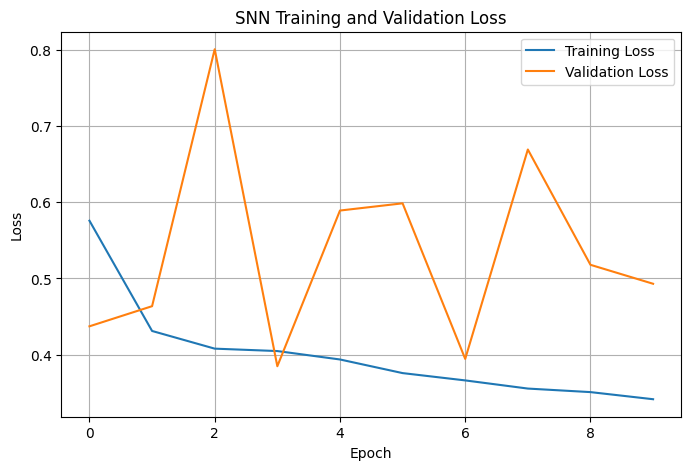

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(
    snn_train_losses,
    label="Training Loss"
)

plt.plot(
    snn_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "SNN Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.show()

SNN predictions

In [54]:
snn_model.eval()

snn_predictions = []
snn_probabilities = []

snn_inference_start = time.time()

with torch.no_grad():

    for batch_x, batch_y in snn_test_loader:

        batch_x = batch_x.to(DEVICE)

        outputs = snn_model(
            batch_x
        )

        logits = outputs.sum(
            dim=0
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = logits.argmax(
            dim=1
        )

        snn_predictions.extend(
            predictions.cpu().numpy()
        )

        snn_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )

snn_inference_time = (
    time.time() -
    snn_inference_start
)

snn_predictions = np.array(
    snn_predictions
)

snn_probabilities = np.array(
    snn_probabilities
)

print(
    "SNN inference time: %.2f seconds"
    % snn_inference_time
)

SNN inference time: 18.41 seconds


SNN metrics

In [55]:
snn_metrics = calculate_metrics(
    y_test,
    snn_predictions,
    snn_probabilities
)

snn_metrics

{'Accuracy': 0.8289803593815295,
 'Precision': 0.5078382039868395,
 'Sensitivity': 0.7821162444113264,
 'Specificity': np.float64(0.838938501488378),
 'F1': 0.6158178831260267,
 'ROC-AUC': np.float64(0.8668761826391801)}

SNN confusion matrix

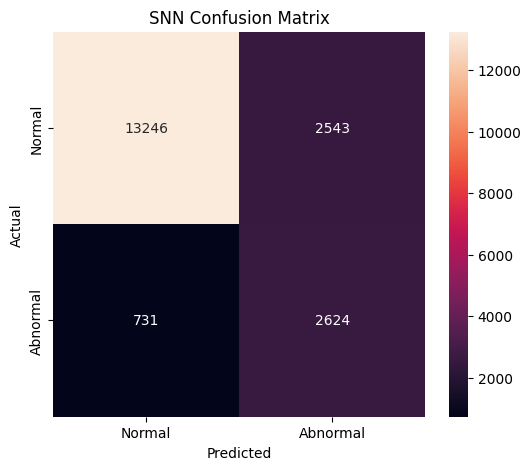

In [56]:
cm = confusion_matrix(
    y_test,
    snn_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Normal", "Abnormal"],
    yticklabels=["Normal", "Abnormal"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "SNN Confusion Matrix"
)

plt.show()

# FINAL MODEL COMPARISON

Create comparison table

In [57]:
results = pd.DataFrame({

    "Random Forest": rf_metrics,
    "1D CNN": cnn_metrics,
    "SNN": snn_metrics

}).T

results

,Accuracy,Precision,Sensitivity,Specificity,F1,ROC-AUC
Random Forest,0.891872,0.672298,0.747243,0.922604,0.707792,0.888076
1D CNN,0.861105,0.580481,0.748137,0.885110,0.653731,0.902921
SNN,0.828980,0.507838,0.782116,0.838939,0.615818,0.866876


Plot model comparison

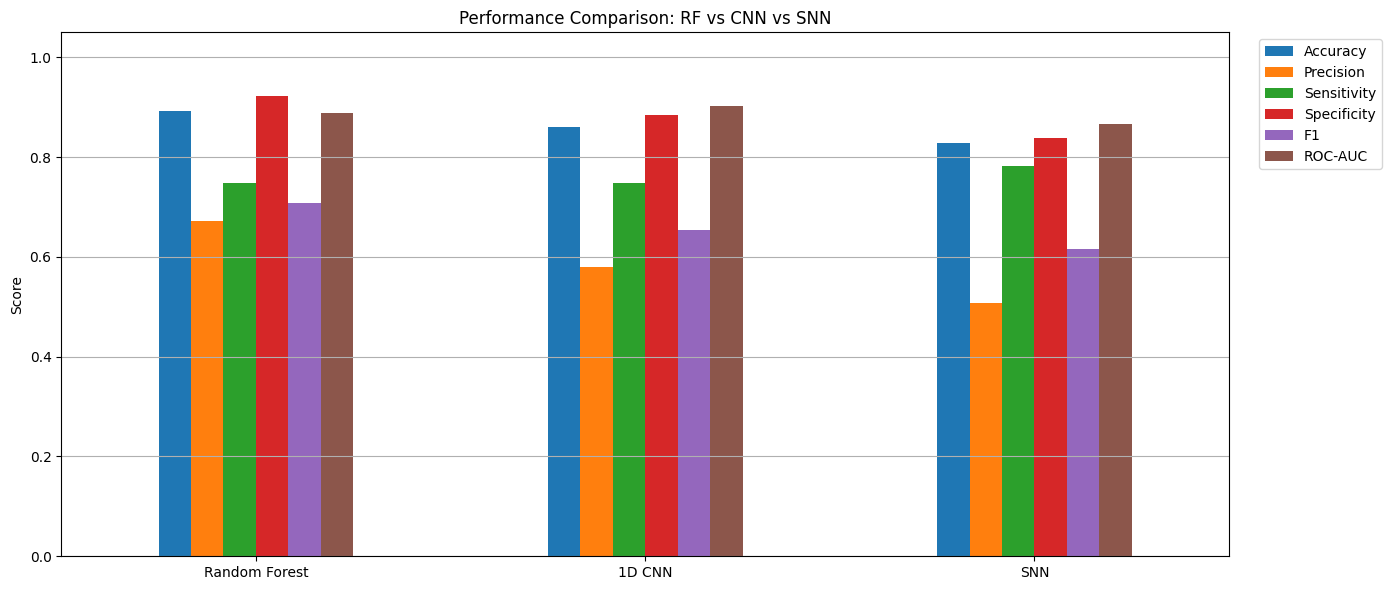

In [58]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1",
    "ROC-AUC"
]

results[metrics_to_plot].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.title(
    "Performance Comparison: RF vs CNN vs SNN"
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

Accuracy and sensitivity comparison

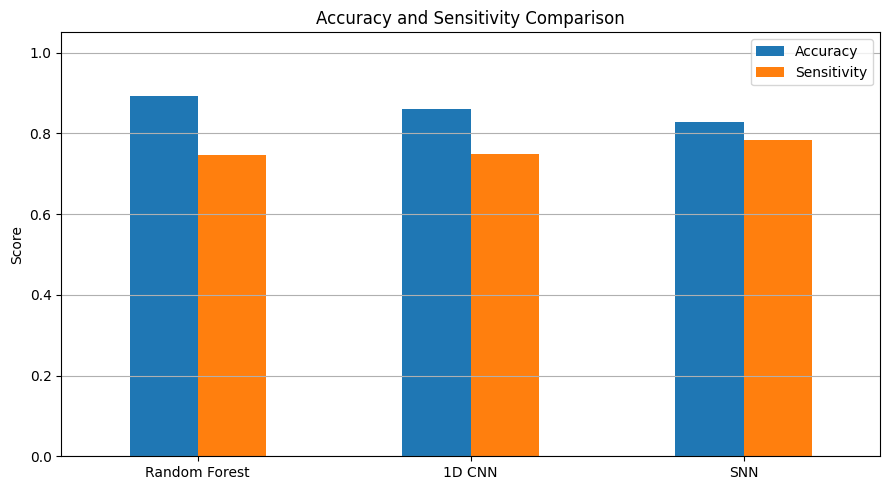

In [59]:
comparison_subset = results[
    ["Accuracy", "Sensitivity"]
]

comparison_subset.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.title(
    "Accuracy and Sensitivity Comparison"
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y"
)

plt.tight_layout()

plt.show()

ROC curves

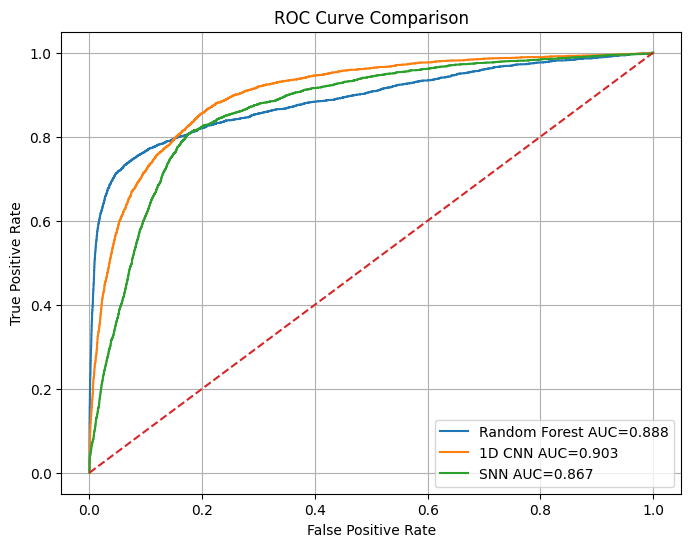

In [60]:
rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_prob
)

cnn_fpr, cnn_tpr, _ = roc_curve(
    y_test,
    cnn_probabilities
)

snn_fpr, snn_tpr, _ = roc_curve(
    y_test,
    snn_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest AUC={rf_metrics['ROC-AUC']:.3f}"
)

plt.plot(
    cnn_fpr,
    cnn_tpr,
    label=f"1D CNN AUC={cnn_metrics['ROC-AUC']:.3f}"
)

plt.plot(
    snn_fpr,
    snn_tpr,
    label=f"SNN AUC={snn_metrics['ROC-AUC']:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve Comparison"
)

plt.legend()

plt.grid(True)

plt.show()

Confusion matrices for all models

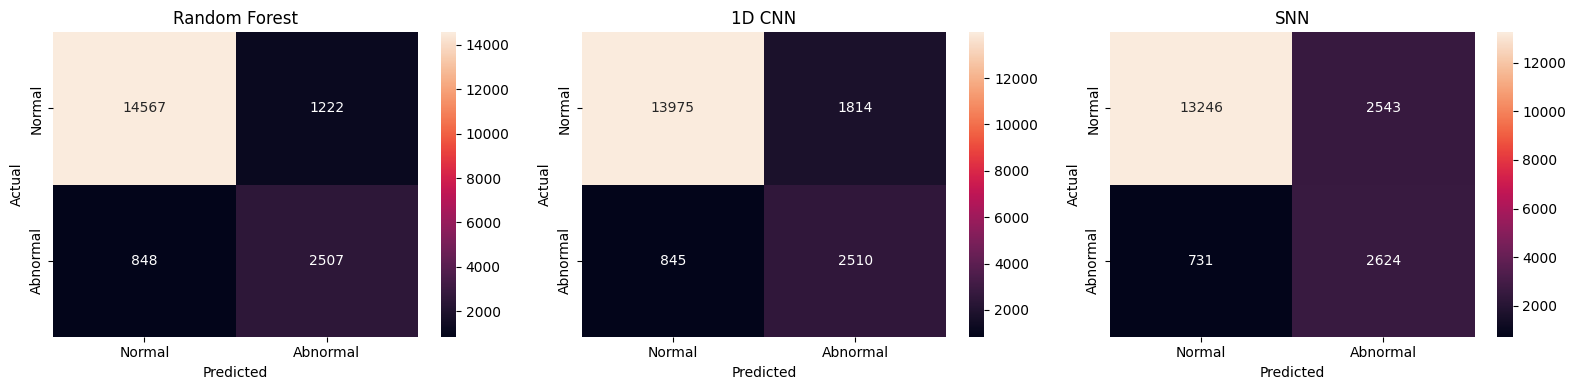

In [61]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4)
)

models_predictions = {
    "Random Forest": rf_pred,
    "1D CNN": cnn_predictions,
    "SNN": snn_predictions
}

for ax, (name, pred) in zip(
    axes,
    models_predictions.items()
):

    cm = confusion_matrix(
        y_test,
        pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        ax=ax,
        xticklabels=["Normal", "Abnormal"],
        yticklabels=["Normal", "Abnormal"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()

plt.show()

Runtime comparison

In [62]:
runtime_results = pd.DataFrame({

    "Model": [
        "Random Forest",
        "1D CNN",
        "SNN"
    ],

    "Training Time (seconds)": [
        rf_train_time,
        cnn_train_time,
        snn_train_time
    ],

    "Inference Time (seconds)": [
        np.nan,
        cnn_inference_time,
        snn_inference_time
    ]

})

runtime_results

,Model,Training Time (seconds),Inference Time (seconds)
0,Random Forest,56.500084,NaN
1,1D CNN,117.600132,2.536413
2,SNN,1580.560016,18.406229


Runtime visualization

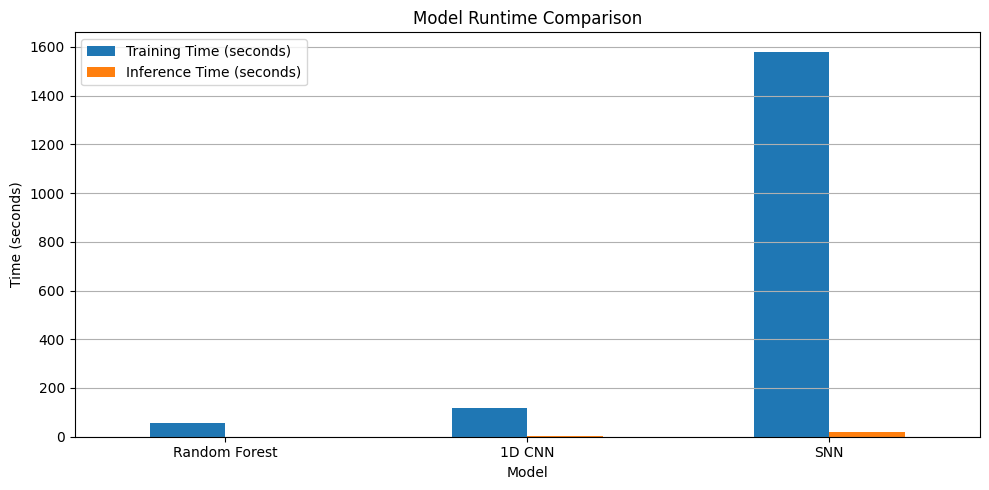

In [63]:
runtime_results.set_index(
    "Model"
)[
    [
        "Training Time (seconds)",
        "Inference Time (seconds)"
    ]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Time (seconds)")

plt.title(
    "Model Runtime Comparison"
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y"
)

plt.tight_layout()

plt.show()

SNN event/spike rate

In [64]:
snn_event_count = np.count_nonzero(
    X_test_spikes
)

snn_total_samples = X_test_spikes.size

snn_event_rate = (
    snn_event_count /
    snn_total_samples
)

print(
    "Total possible input events:",
    snn_total_samples
)

print(
    "Actual LC events:",
    snn_event_count
)

print(
    "Event rate:",
    snn_event_rate
)

print(
    "Input sparsity:",
    1 - snn_event_rate
)

Total possible input events: 2450432
Actual LC events: 577150
Event rate: 0.23552989840158797
Input sparsity: 0.764470101598412


LC threshold vs event rate

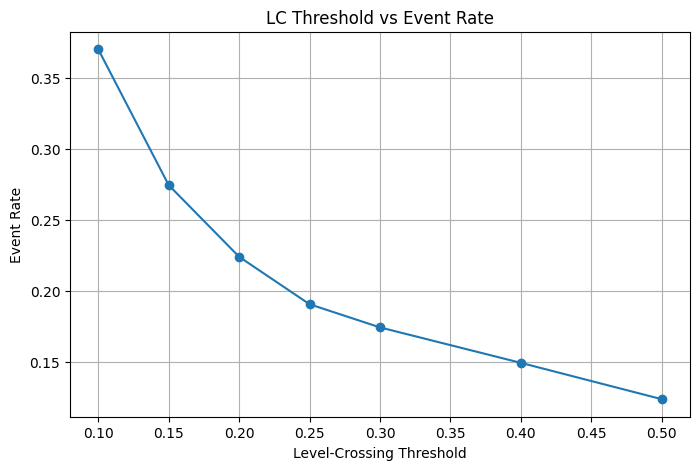

In [65]:
thresholds = [
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50
]

event_rates = []

sample_count = min(
    2000,
    len(X_test)
)

for threshold in thresholds:

    total_events = 0
    total_samples = 0

    for beat in X_test[:sample_count]:

        spikes = level_crossing_encode(
            beat,
            threshold
        )

        total_events += np.count_nonzero(
            spikes
        )

        total_samples += len(spikes)

    event_rates.append(
        total_events / total_samples
    )

plt.figure(figsize=(8, 5))

plt.plot(
    thresholds,
    event_rates,
    marker="o"
)

plt.xlabel(
    "Level-Crossing Threshold"
)

plt.ylabel(
    "Event Rate"
)

plt.title(
    "LC Threshold vs Event Rate"
)

plt.grid(True)

plt.show()

Save the results

In [66]:
results.to_csv(
    "NeuroCardio_model_results.csv"
)

runtime_results.to_csv(
    "NeuroCardio_runtime_results.csv",
    index=False
)

print("Results saved.")

Results saved.


Download results

In [67]:
from google.colab import files

files.download(
    "NeuroCardio_model_results.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Final summary

In [68]:
print("=" * 60)
print("NEUROCARDIO — FINAL MODEL COMPARISON")
print("=" * 60)

display(results.round(4))

print("\nLC EVENT RATE")
print(
    f"{snn_event_rate:.4f}"
)

print("\nINPUT SPARSITY")
print(
    f"{1 - snn_event_rate:.4f}"
)

print("\nBest model by accuracy:")

best_model = results["Accuracy"].idxmax()

print(
    best_model,
    "->",
    results.loc[
        best_model,
        "Accuracy"
    ]
)

print("=" * 60)

NEUROCARDIO — FINAL MODEL COMPARISON


,Accuracy,Precision,Sensitivity,Specificity,F1,ROC-AUC
Random Forest,0.8919,0.6723,0.7472,0.9226,0.7078,0.8881
1D CNN,0.8611,0.5805,0.7481,0.8851,0.6537,0.9029
SNN,0.8290,0.5078,0.7821,0.8389,0.6158,0.8669



LC EVENT RATE
0.2355

INPUT SPARSITY
0.7645

Best model by accuracy:
Random Forest -> 0.8918721270371918
